# Sentiment Analysis using NLTK / Watson Tone Analyzer

**Problem statement:** Sentiment Analysis using NLTK / Watson –Tone analyzer

**Objectives**
1. To study and explore IBM Watson Tone Analyzer API.
2. To learn concepts of sentiment analysis using NLTK.

This notebook covers:

1. **2 NLTK classifiers**: Naive Bayes and Logistic Regression (maximum entropy), both trained on labelled data
2. **2 corpora**: NLTK `twitter_samples` (English tweets) and **AI4Bharat IndicSentiment** (reviews in Hindi and English)
3. **4 performance metrics**: accuracy, precision, recall, F1
4. **IBM Watson Tone Analyzer** (optional, needs IBM Cloud credentials)

Run all cells in order. A CPU runtime is enough.


## 0. Setup

In [42]:
!pip install -q nltk scikit-learn pandas matplotlib requests huggingface_hub


In [43]:
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

for pkg in ["twitter_samples"]:
    nltk.download(pkg, quiet=True)

random.seed(0)
print("NLTK", nltk.__version__)


NLTK 3.9.1


## 1. Corpus A — NLTK `twitter_samples`

5,000 positive and 5,000 negative tweets, shipped with NLTK. These are used to **train**
the Naive Bayes classifier (4,000 per class) and to **test** both models (the other
1,000 per class).


In [44]:
from nltk.corpus import twitter_samples

pos_tweets = twitter_samples.strings("positive_tweets.json")
neg_tweets = twitter_samples.strings("negative_tweets.json")
print("positive tweets:", len(pos_tweets), "| negative tweets:", len(neg_tweets))

random.shuffle(pos_tweets)
random.shuffle(neg_tweets)
pos_train, pos_test = pos_tweets[:4000], pos_tweets[4000:]
neg_train, neg_test = neg_tweets[:4000], neg_tweets[4000:]

for t in pos_tweets[:2]:
    print("[positive]", t)
for t in neg_tweets[:2]:
    print("[negative]", t)


positive tweets: 5000 | negative tweets: 5000
[positive] over slept:):):)
[positive] @Clareyh Yeah, it's a classy look :-). I've seen people attached to all sorts of 'life saving' equipment, some in beds,having their fix :-0)
[negative] Why didn't I glo up yet??? :((
[negative] @NinaSarto pm me :(


## 2. Models — Naive Bayes and Logistic Regression

Both models learn from labelled examples. Features are simply "this word is present".
Handles, links and tokens without letters (emoticons, numbers) are removed, so the models
learn from **words** only.

- **Naive Bayes** (`nltk.classify.NaiveBayesClassifier`): counts how often each word appears
  in positive and in negative texts, and picks the class with the higher probability.
- **Logistic Regression** (maximum entropy, through NLTK's `SklearnClassifier` wrapper): learns
  one weight per word and combines the weights to give the probability of each class.
  Unlike Naive Bayes, it does not assume that words are independent.


In [45]:
from nltk.tokenize import TweetTokenizer
from nltk.classify import NaiveBayesClassifier, SklearnClassifier
from sklearn.linear_model import LogisticRegression

tokenizer = TweetTokenizer(preserve_case=False, reduce_len=True, strip_handles=True)

def features(text):
    text = re.sub(r"https?://\S+", "", text)
    words = [w for w in tokenizer.tokenize(text) if re.search(r"[a-z]", w)]
    return {w: True for w in words}

def train_models(texts, labels, feat):
    data = [(feat(t), l) for t, l in zip(texts, labels)]
    nb_model = NaiveBayesClassifier.train(data)
    lr_model = SklearnClassifier(LogisticRegression(max_iter=1000)).train(data)
    return nb_model, lr_model

train_texts = pos_train + neg_train
train_labels = ["positive"] * len(pos_train) + ["negative"] * len(neg_train)
nb, lr = train_models(train_texts, train_labels, features)

print("Trained both models on", len(train_texts), "tweets")
nb.show_most_informative_features(10)


Trained both models on 8000 tweets
Most Informative Features
                     bam = True           positi : negati =     22.3 : 1.0
                     sad = True           negati : positi =     21.9 : 1.0
                 arrived = True           positi : negati =     21.4 : 1.0
                     x15 = True           negati : positi =     17.7 : 1.0
                   tired = True           negati : positi =     17.0 : 1.0
                    glad = True           positi : negati =     15.4 : 1.0
                    lost = True           negati : positi =     15.0 : 1.0
                   loves = True           positi : negati =     15.0 : 1.0
               community = True           positi : negati =     14.3 : 1.0
                     ugh = True           negati : positi =     14.3 : 1.0


## 3. Performance Metrics

| Metric | Measures |
|---|---|
| **Accuracy** | share of texts given the correct label |
| **Precision** | of the texts labelled a class, how many truly belong to it (macro average) |
| **Recall** | of the texts that truly belong to a class, how many were found (macro average) |
| **F1** | harmonic mean of precision and recall (macro average) |

Both models are tested on the **2,000 held-out tweets** of Corpus A.


In [46]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def scores(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"Accuracy": round(accuracy_score(y_true, y_pred), 4),
            "Precision": round(p, 4), "Recall": round(r, 4), "F1": round(f, 4),
            "n": len(y_true)}

# Corpus A: held-out tweets
test_texts = pos_test + neg_test
test_true = ["positive"] * len(pos_test) + ["negative"] * len(neg_test)
test_feats = [features(t) for t in test_texts]

results_df = pd.DataFrame([
    {"Model": "Naive Bayes", "Corpus": "A: twitter_samples (test)", **scores(test_true, nb.classify_many(test_feats))},
    {"Model": "Logistic Regression", "Corpus": "A: twitter_samples (test)", **scores(test_true, lr.classify_many(test_feats))},
]).set_index(["Corpus", "Model"])
results_df


Accuracy  Precision  Recall  \
Corpus                    Model                                              
A: twitter_samples (test) Naive Bayes             0.751     0.7518   0.751   
                          Logistic Regression     0.766     0.7664   0.766   

                                                   F1     n  
Corpus                    Model                              
A: twitter_samples (test) Naive Bayes          0.7508  2000  
                          Logistic Regression  0.7659  2000

## 4. Corpus B — AI4Bharat IndicSentiment (Hindi and English)

[AI4Bharat](https://ai4bharat.iitm.ac.in/) (IIT Madras) publishes open corpora for Indian
languages. **IndicSentiment** has product reviews with a positive or negative label. Each
review is given in an Indian language and in English, so one dataset lets us test **two
languages**. This notebook uses the Hindi version (about 1,000 reviews).

- **English reviews:** both models trained on tweets (Corpus A), and both models trained on
  these reviews.
- **Hindi reviews:** both models trained on the Hindi reviews. Tweet-trained English models
  cannot read Hindi, so they are not tested here.
- 70% of the reviews are used for training and 30% for testing.

The Hindi test file (`data/test/hi.json`) is downloaded from Hugging Face. If the name or the columns differ from what the
cell expects, it prints what it found instead of stopping the notebook.


In [47]:
from huggingface_hub import hf_hub_download

indic_df = None
raw = None
try:
    # The dataset repo uses a loading script, which `load_dataset` no longer runs,
    # so the raw Hindi test file is downloaded directly.
    path = hf_hub_download("ai4bharat/IndicSentiment", "data/test/hi.json", repo_type="dataset")
    try:
        raw = pd.read_json(path, lines=True)
    except ValueError:
        raw = pd.read_json(path)
    cols = {c.lower().replace(" ", "_"): c for c in raw.columns}
    hi_col = next(c for k, c in cols.items() if "indic" in k)
    en_col = next(c for k, c in cols.items() if "english" in k)
    lab_col = next(c for k, c in cols.items() if k == "label")
    indic_df = pd.DataFrame({"hindi": raw[hi_col], "english": raw[en_col],
                             "label": raw[lab_col].astype(str).str.lower()})
    indic_df = indic_df[indic_df["label"].isin(["positive", "negative"])].reset_index(drop=True)
    print(len(indic_df), "reviews |", indic_df["label"].value_counts().to_dict())
except Exception as e:
    print("Could not load IndicSentiment:", type(e).__name__, e)
    if raw is not None:
        print("Columns found:", list(raw.columns))

if indic_df is not None and len(indic_df):
    pd.set_option("display.max_colwidth", 90)
    display(indic_df.head(4))


998 reviews | {'positive': 506, 'negative': 492}


,hindi,english,label
0,केवल आईआईएसईआईआर और सीएसआईआर कर्मचारी के बच्चों के लिए प्ले एरिया।,Restricted play area for only IISERs and CSIR employee's kids.,negative
1,होस्ट अमेजिंग थे और पूरी प्रॉपर्टी से चेरी और सेब के पेड़ों से घिरे पहाड़ के दृश्य के ...,The hosts were amazing and the ambience is breathtakingly beautiful with mountain view...,positive
2,"""बहुत कम ब्रांड हैं जो इस प्राइस रेंज में कुर्सियों के लिए एडजस्टेबल हेडरेस्ट देते हैं...",One of the very few brands to have adjustable headrests for chairs in this price range...,positive
3,बीआईएस सर्टिफिकेशन और स्मार्ट आईसी के बारे में कोई रिव्यु नहीं,No reviews about BIS certification and smart IC,negative


In [48]:
import unicodedata

def hi_features(text):
    # split on spaces, drop punctuation/symbol characters (category P or S), keep Devanagari marks
    words = []
    for w in str(text).lower().split():
        w = "".join(ch for ch in w if unicodedata.category(ch)[0] not in "PS")
        if w:
            words.append(w)
    return {w: True for w in words}

if indic_df is None or not len(indic_df):
    print("Corpus B not loaded - skipping this cell.")
else:
    order = list(range(len(indic_df)))
    random.shuffle(order)
    cut = int(0.7 * len(order))
    train_c, test_c = indic_df.iloc[order[:cut]], indic_df.iloc[order[cut:]]
    y = list(test_c["label"])

    nb_en, lr_en = train_models(train_c["english"], train_c["label"], features)
    nb_hi, lr_hi = train_models(train_c["hindi"], train_c["label"], hi_features)

    en_feats = [features(t) for t in test_c["english"]]
    hi_feats = [hi_features(t) for t in test_c["hindi"]]
    indic_results = pd.DataFrame([
        {"Language": "English", "Model": "Naive Bayes (trained on tweets)",         **scores(y, nb.classify_many(en_feats))},
        {"Language": "English", "Model": "Logistic Regression (trained on tweets)", **scores(y, lr.classify_many(en_feats))},
        {"Language": "English", "Model": "Naive Bayes (trained on reviews)",         **scores(y, nb_en.classify_many(en_feats))},
        {"Language": "English", "Model": "Logistic Regression (trained on reviews)", **scores(y, lr_en.classify_many(en_feats))},
        {"Language": "Hindi",   "Model": "Naive Bayes (trained on reviews)",         **scores(y, nb_hi.classify_many(hi_feats))},
        {"Language": "Hindi",   "Model": "Logistic Regression (trained on reviews)", **scores(y, lr_hi.classify_many(hi_feats))},
    ]).set_index(["Language", "Model"])
    print("Most informative Hindi words (Naive Bayes):")
    nb_hi.show_most_informative_features(10)
    display(indic_results)


Most informative Hindi words (Naive Bayes):
Most Informative Features
                   आसानी = True           positi : negati =     12.5 : 1.0
                    खराब = True           negati : positi =     11.4 : 1.0
                     ठीक = True           negati : positi =      9.4 : 1.0
                 मुश्किल = True           negati : positi =      8.7 : 1.0
                  कभीकभी = True           negati : positi =      8.0 : 1.0
                 हालांकि = True           negati : positi =      8.0 : 1.0
                 बेहतरीन = True           positi : negati =      7.5 : 1.0
                   अक्सर = True           negati : positi =      7.3 : 1.0
                 डिज़ाइन = True           positi : negati =      6.7 : 1.0
                  ज़्यादा = True           negati : positi =      6.6 : 1.0


Accuracy  Precision  \
Language Model                                                           
English  Naive Bayes (trained on tweets)             0.6100     0.6156   
         Logistic Regression (trained on tweets)     0.6867     0.6916   
         Naive Bayes (trained on reviews)            0.7800     0.7802   
         Logistic Regression (trained on reviews)    0.8067     0.8067   
Hindi    Naive Bayes (trained on reviews)            0.7967     0.8026   
         Logistic Regression (trained on reviews)    0.8400     0.8401   

                                                   Recall      F1    n  
Language Model                                                          
English  Naive Bayes (trained on tweets)           0.6100  0.6052  300  
         Logistic Regression (trained on tweets)   0.6867  0.6846  300  
         Naive Bayes (trained on reviews)          0.7800  0.7800  300  
         Logistic Regression (trained on reviews)  0.8067  0.8067  300  
Hindi    Naive Bayes (trained on reviews)          0.7967  0.7957  300  
         Logistic Regression (trained on reviews)  0.8400  0.8400  300

## 5. IBM Watson Tone Analyzer (optional)

Tone Analyzer is a cloud service: you send text, it returns **tones** with a score from
0 to 1 (for example anger, fear, joy, sadness, analytical, confident, tentative). It
needs an IBM Cloud account, an API key and a service URL, and **cannot run without them**.

Two things to know before relying on it:

- IBM's Python package `ibm-watson` has `ToneAnalyzerV3` in version 5.3.0 but **not** in
  6.1.0 or later. So this cell calls the service's REST API directly with `requests`,
  which works with any package version.
- The service may no longer be available on IBM Cloud. If your IBM Cloud account has no
  Tone Analyzer instance, or the call fails, the cell prints the error and the rest of the
  notebook is not affected.

To run it, paste the `apikey` and `url` from your service credentials below.


In [49]:
import requests

WATSON_APIKEY = ""   # paste your Tone Analyzer apikey here
WATSON_URL = ""      # paste your service url here, e.g. https://api.eu-gb.tone-analyzer.watson.cloud.ibm.com/instances/<id>

watson_samples = [
    "I am so happy with the service, everything was perfect!",
    "I am terrified that the results will be bad.",
    "The treatment reduced symptoms in most patients, and recovery was faster than expected.",
    "The stock plunged 18% after the company missed earnings and cut its outlook.",
    "Oh fantastic, the wifi died again right before my meeting.",
]

def watson_tones(text):
    # 1) exchange the API key for an IAM access token
    token = requests.post(
        "https://iam.cloud.ibm.com/identity/token",
        data={"grant_type": "urn:ibm:params:oauth:grant-type:apikey", "apikey": WATSON_APIKEY},
        timeout=30,
    )
    token.raise_for_status()
    # 2) call the Tone Analyzer v3 endpoint
    resp = requests.post(
        f"{WATSON_URL}/v3/tone",
        params={"version": "2017-09-21"},
        headers={"Authorization": f"Bearer {token.json()['access_token']}"},
        json={"text": text},
        timeout=30,
    )
    resp.raise_for_status()
    return [(t["tone_name"], round(t["score"], 2)) for t in resp.json()["document_tone"]["tones"]]

if not WATSON_APIKEY or not WATSON_URL:
    print("No Watson credentials set - skipping this section.")
else:
    try:
        for s in watson_samples:
            print(s, "->", watson_tones(s) or "no tone above the service threshold")
    except Exception as e:
        print("Watson call failed:", type(e).__name__, e)


No Watson credentials set - skipping this section.


## 6. Visual analysis

Three views of the results above:

1. **Confusion matrices** — for each test, how many positive and negative texts were labelled
   correctly or wrongly. Each cell shows the count and the share of its true class.
2. **Accuracy of every setup**, side by side.
3. **Words with the largest weight** in the Logistic Regression models — what each model
   learned.


In [50]:
# VIZ8 — shared helpers
import glob, subprocess
from matplotlib import font_manager as fm
from sklearn.metrics import confusion_matrix

BLUE, ORANGE = "#2a78d6", "#eb6834"      # series 1 and 2 (same colour = same model in every chart)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
classes = ["positive", "negative"]

def hindi_font():
    """Matplotlib needs a Devanagari font to draw Hindi words; install Noto if it is missing."""
    pattern = "/usr/share/fonts/**/NotoSansDevanagari-Regular.ttf"
    paths = glob.glob(pattern, recursive=True)
    if not paths:
        subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-core"], capture_output=True)
        paths = glob.glob(pattern, recursive=True)
    if paths:
        fm.fontManager.addfont(paths[0])
        prop = fm.FontProperties(fname=paths[0])
        # DejaVu Sans first (Latin, symbols), Noto Sans Devanagari as the fallback for Hindi
        plt.rcParams["font.family"] = ["DejaVu Sans", prop.get_name()]
        return prop
    print("No Devanagari font found: Hindi labels may appear as boxes.")
    return None

def plot_cm(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n{share[i, j]:.0%}", ha="center", va="center",
                    color="white" if share[i, j] > 0.5 else "black", fontsize=11)
    ax.set_xticks([0, 1]); ax.set_xticklabels(classes)
    ax.set_yticks([0, 1]); ax.set_yticklabels(classes)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(title, fontsize=10)
    ax.spines[:].set_visible(False)


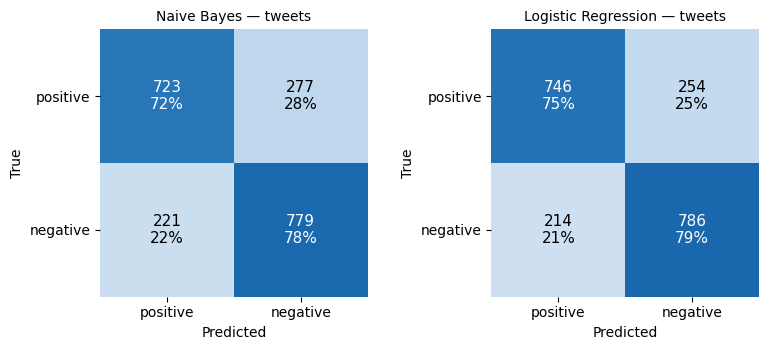

In [51]:
# Confusion matrices: tweets (Corpus A)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
plot_cm(axes[0], test_true, nb.classify_many(test_feats), "Naive Bayes — tweets")
plot_cm(axes[1], test_true, lr.classify_many(test_feats), "Logistic Regression — tweets")
plt.tight_layout()
plt.show()


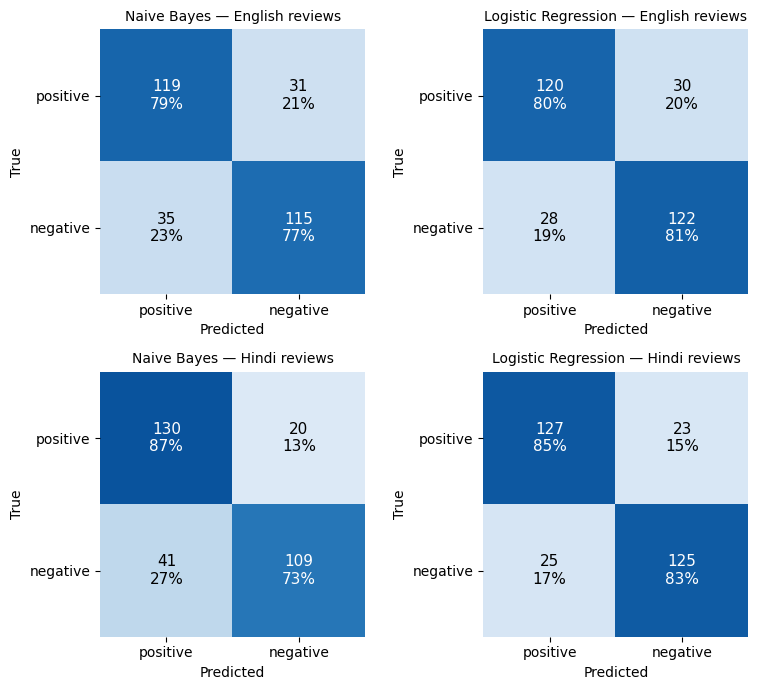

In [52]:
# Confusion matrices: IndicSentiment (Corpus B)
if indic_df is None or not len(indic_df):
    print("Corpus B not loaded - skipping.")
else:
    fig, axes = plt.subplots(2, 2, figsize=(8, 7))
    plot_cm(axes[0, 0], y, nb_en.classify_many(en_feats), "Naive Bayes — English reviews")
    plot_cm(axes[0, 1], y, lr_en.classify_many(en_feats), "Logistic Regression — English reviews")
    plot_cm(axes[1, 0], y, nb_hi.classify_many(hi_feats), "Naive Bayes — Hindi reviews")
    plot_cm(axes[1, 1], y, lr_hi.classify_many(hi_feats), "Logistic Regression — Hindi reviews")
    plt.tight_layout()
    plt.show()


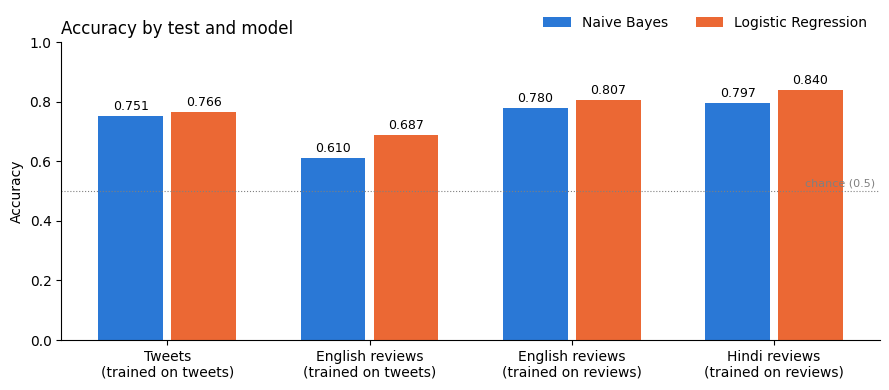

In [53]:
# Accuracy of every setup, Naive Bayes vs Logistic Regression
setups = [("Tweets\n(trained on tweets)", results_df.loc[("A: twitter_samples (test)", "Naive Bayes"), "Accuracy"],
                                          results_df.loc[("A: twitter_samples (test)", "Logistic Regression"), "Accuracy"])]
if indic_df is not None and len(indic_df):
    r = indic_results["Accuracy"]
    setups += [
        ("English reviews\n(trained on tweets)",   r[("English", "Naive Bayes (trained on tweets)")],   r[("English", "Logistic Regression (trained on tweets)")]),
        ("English reviews\n(trained on reviews)",  r[("English", "Naive Bayes (trained on reviews)")],  r[("English", "Logistic Regression (trained on reviews)")]),
        ("Hindi reviews\n(trained on reviews)",    r[("Hindi", "Naive Bayes (trained on reviews)")],    r[("Hindi", "Logistic Regression (trained on reviews)")]),
    ]

x = np.arange(len(setups)); w = 0.36
fig, ax = plt.subplots(figsize=(9, 4))
b1 = ax.bar(x - w/2, [s[1] for s in setups], w - 0.04, color=BLUE, label="Naive Bayes")
b2 = ax.bar(x + w/2, [s[2] for s in setups], w - 0.04, color=ORANGE, label="Logistic Regression")
for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f"{bar.get_height():.3f}",
                ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([s[0] for s in setups])
ax.set_ylim(0, 1); ax.set_ylabel("Accuracy")
ax.axhline(0.5, color="grey", lw=0.8, ls=":")
ax.text(len(setups) - 0.5, 0.51, "chance (0.5)", ha="right", va="bottom", fontsize=8, color="grey")
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2)
ax.set_title("Accuracy by test and model", loc="left")
plt.tight_layout()
plt.show()


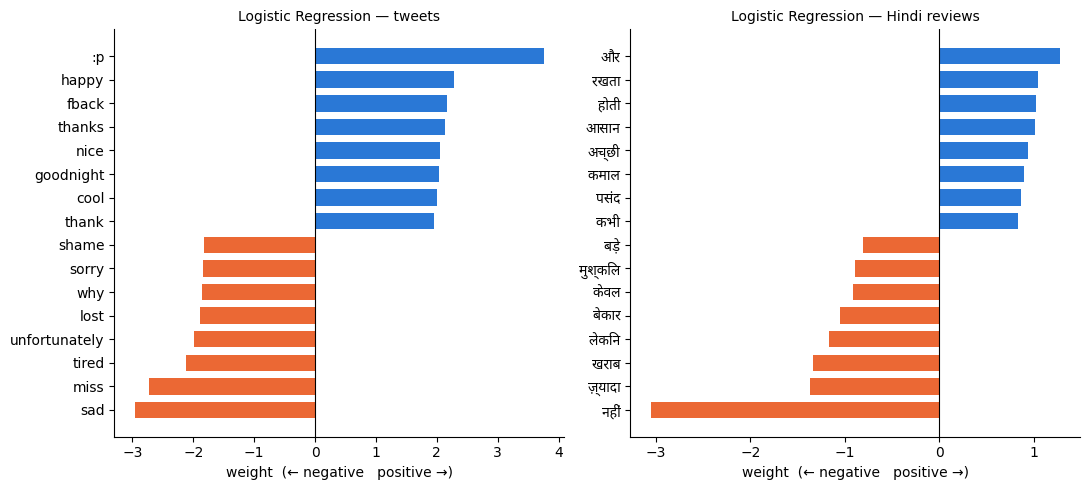

In [54]:
# Words with the largest Logistic Regression weights
def top_words(model, k=8):
    names = model._vectorizer.get_feature_names_out()
    coef = model._clf.coef_[0]
    if model._clf.classes_[1] == "negative":     # make positive weight = positive sentiment
        coef = -coef
    order = np.argsort(coef)
    return [(names[i], coef[i]) for i in order[:k]] + [(names[i], coef[i]) for i in order[-k:]]

def plot_top_words(ax, model, title):
    items = top_words(model)
    words = [w for w, _ in items]; vals = [v for _, v in items]
    ax.barh(range(len(items)), vals, color=[ORANGE if v < 0 else BLUE for v in vals], height=0.7)
    ax.set_yticks(range(len(items))); ax.set_yticklabels(words)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("weight  (← negative   positive →)")
    ax.set_title(title, fontsize=10)

hf = hindi_font()
ncols = 2 if (indic_df is not None and len(indic_df)) else 1
fig, axes = plt.subplots(1, ncols, figsize=(5.5 * ncols, 5), squeeze=False)
plot_top_words(axes[0, 0], lr, "Logistic Regression — tweets")
if ncols == 2:
    plot_top_words(axes[0, 1], lr_hi, "Logistic Regression — Hindi reviews")
plt.tight_layout()
plt.show()


## Conclusion

Hence, learned the concepts of sentiment analysis using IBM Watson Tone analyzer API / NLTK.

This notebook demonstrated:

- **Two NLTK classifiers**: Naive Bayes and Logistic Regression (maximum entropy)
- **Two corpora**: NLTK `twitter_samples` and AI4Bharat IndicSentiment (Hindi and English)
- **Four metrics**: accuracy, precision, recall, F1
- **Watson Tone Analyzer**: a REST-API call, which runs only with IBM Cloud credentials

Compare the two models on tweets and on reviews, and in Hindi and English: a model learns the
language and domain of its training data, so the same code works for Hindi once it is trained on Hindi text.
